# Time-Series Analysis of NOAA Daily Temperature Observations

This notebook explores multi-station NOAA temperature observations over time. It:

1. Loads and inspects the data
2. Aggregates observations by date, week and month
3. Computes a 30-day rolling average to smooth day-to-day noise
4. Examines seasonal patterns by month and day of week
5. Plots the raw observations together with the rolling and monthly trends

**Note:** the CSV contains several station observations per date, so observations are averaged by date before any rolling or resampling step.

## 1. Imports

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## 2. Load and explore the data

The `date` column is parsed to datetime and kept as a regular column (not the index), and the data is sorted chronologically. `df.info()` shows column types, non-null counts and memory usage.

In [2]:
df = pd.read_csv('noaa - 5000.csv')
df['date'] = pd.to_datetime(df['date'])
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['day'] = df['date'].dt.day
df = df.sort_values('date').reset_index(drop=True)

df.info()

<class 'pandas.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 35 columns):
 #   Column                Non-Null Count  Dtype         
---  ------                --------------  -----         
 0   stn                   5000 non-null   int64         
 1   wban                  5000 non-null   int64         
 2   date                  5000 non-null   datetime64[us]
 3   year                  5000 non-null   int32         
 4   mo                    5000 non-null   int64         
 5   da                    5000 non-null   int64         
 6   temp                  5000 non-null   float64       
 7   count_temp            5000 non-null   int64         
 8   dewp                  5000 non-null   float64       
 9   count_dewp            5000 non-null   int64         
 10  slp                   5000 non-null   float64       
 11  count_slp             5000 non-null   int64         
 12  stp                   5000 non-null   float64       
 13  count_stp             5000 no

In [3]:
df.head()

,stn,wban,date,year,mo,da,temp,count_temp,dewp,count_dewp,slp,count_slp,stp,count_stp,visib,count_visib,wdsp,count_wdsp,mxpsd,gust,max,flag_max,min,flag_min,prcp,flag_prcp,sndp,fog,rain_drizzle,snow_ice_pellets,hail,thunder,tornado_funnel_cloud,month,day
0,242610,99999,2025-01-01,2025,1,1,-28.6,5,-36.0,5,1019.7,5,951.0,5,5.1,5,0.0,5,999.9,999.9,-23.3,NaN,-29.7,*,0.03,E,999.9,0,0,1,0,0,0,1,1
1,422990,99999,2025-01-01,2025,1,1,53.0,4,43.5,4,9999.9,0,825.2,4,3.4,4,1.2,4,1.9,999.9,58.6,*,45.5,NaN,0.00,I,999.9,0,0,0,0,0,0,1,1
2,431110,99999,2025-01-01,2025,1,1,69.4,4,56.5,4,9999.9,0,865.2,4,1.9,4,6.2,4,9.9,999.9,77.9,NaN,58.1,NaN,0.00,I,999.9,0,0,0,0,0,0,1,1
3,679690,99999,2025-01-01,2025,1,1,82.7,4,9999.9,0,9999.9,0,999.9,0,14.0,4,3.0,4,8.0,999.9,90.0,*,66.9,NaN,0.00,G,999.9,0,1,0,0,1,0,1,1
4,432780,99999,2025-01-01,2025,1,1,79.7,5,74.9,5,1013.9,5,13.2,5,3.6,5,3.4,5,4.1,999.9,86.2,NaN,74.7,NaN,0.00,I,999.9,0,0,0,0,0,0,1,1


## 3. Weekly and monthly averages

Observations are grouped by calendar week and month-end using `pd.Grouper`.

In [4]:
weekly_temp = df.groupby(pd.Grouper(key='date', freq='W'))['temp'].mean().reset_index()
monthly_temp = df.groupby(pd.Grouper(key='date', freq='ME'))['temp'].mean().reset_index()

print(weekly_temp.head())
print(monthly_temp.head())

        date       temp
0 2025-01-05  46.941111
1 2025-01-12  46.189362
2 2025-01-19  47.220301
3 2025-01-26  43.294872
4 2025-02-02  46.509868
        date       temp
0 2025-01-31  45.653073
1 2025-02-28  47.156707
2 2025-03-31  54.819702
3 2025-04-30  61.089535
4 2025-05-31  66.567719


## 4. Daily average and 30-day rolling average

Multiple stations report on the same date, so temperatures are averaged by date first. A 30-day rolling mean (`min_periods=1`) then smooths short-term variation.

In [5]:
daily_temp_df = df.groupby('date')['temp'].mean().sort_index().to_frame()
daily_temp_df['temp_30d_ma'] = daily_temp_df['temp'].rolling(window=30, min_periods=1).mean()
print(daily_temp_df.head(10))

                 temp  temp_30d_ma
date                              
2025-01-01  50.387500    50.387500
2025-01-02  45.115000    47.751250
2025-01-03  48.352632    47.951711
2025-01-04  43.564286    46.854854
2025-01-05  47.028571    46.889598
2025-01-06  42.575000    46.170498
2025-01-07  38.847619    45.124373
2025-01-08  42.275000    44.768201
2025-01-09  47.921053    45.118518
2025-01-10  50.200000    45.626666


### Date slicing

Because `daily_temp_df` has a `DatetimeIndex`, `.loc` can slice it by date. Here is the first 90 days of the record, and the same window as a weekly and monthly resample.

In [6]:
start = daily_temp_df.index.min()
end = start + pd.Timedelta(days=89)

first_90_days = daily_temp_df.loc[start:end]
print(first_90_days[['temp', 'temp_30d_ma']].describe())

print(first_90_days['temp'].resample('W').mean().head())
print(first_90_days['temp'].resample('MS').mean())

            temp  temp_30d_ma
count  90.000000    90.000000
mean   50.368823    48.668592
std     8.038265     2.676596
min    32.610448    44.768201
25%    44.637500    46.875859
50%    50.200000    47.494966
75%    55.256100    49.482231
max    76.600000    55.606451
date
2025-01-05    46.889598
2025-01-12    45.981455
2025-01-19    48.628614
2025-01-26    45.990683
2025-02-02    45.941464
Freq: W-SUN, Name: temp, dtype: float64
date
2025-01-01    46.684575
2025-02-01    48.817544
2025-03-01    55.454227
Freq: MS, Name: temp, dtype: float64


## 5. Seasonal patterns

Monthly averages (with min–max range) show the annual cycle, and day-of-week averages check for any weekly pattern. The month × day-of-week matrix combines both views.

            temp month_name day_of_week
date                                   
2025-01-01 -28.6    January   Wednesday
2025-01-01  53.0    January   Wednesday
2025-01-01  69.4    January   Wednesday
2025-01-01  82.7    January   Wednesday
2025-01-01  79.7    January   Wednesday
--- Monthly Seasonal Averages ---
   month_num month_name   avg_temp  min_temp  max_temp  count
0          1    January  45.653073     -57.2      93.4    667
1          2   February  47.156707     -59.1     102.2    656
2          3      March  54.819702     -83.0     102.2    604
3          4      April  61.089535     -97.0     104.3    602
4          5        May  66.567719    -105.3     104.0    570
5          6       June  67.142985     -98.9     107.5    670
6          7       July  70.449718    -102.1     102.4    710
7          8     August  68.461036     -95.8     109.4    521

--- Day-of-Week Averages ---
                  mean        std  count
day_of_week                             
Monday       61.

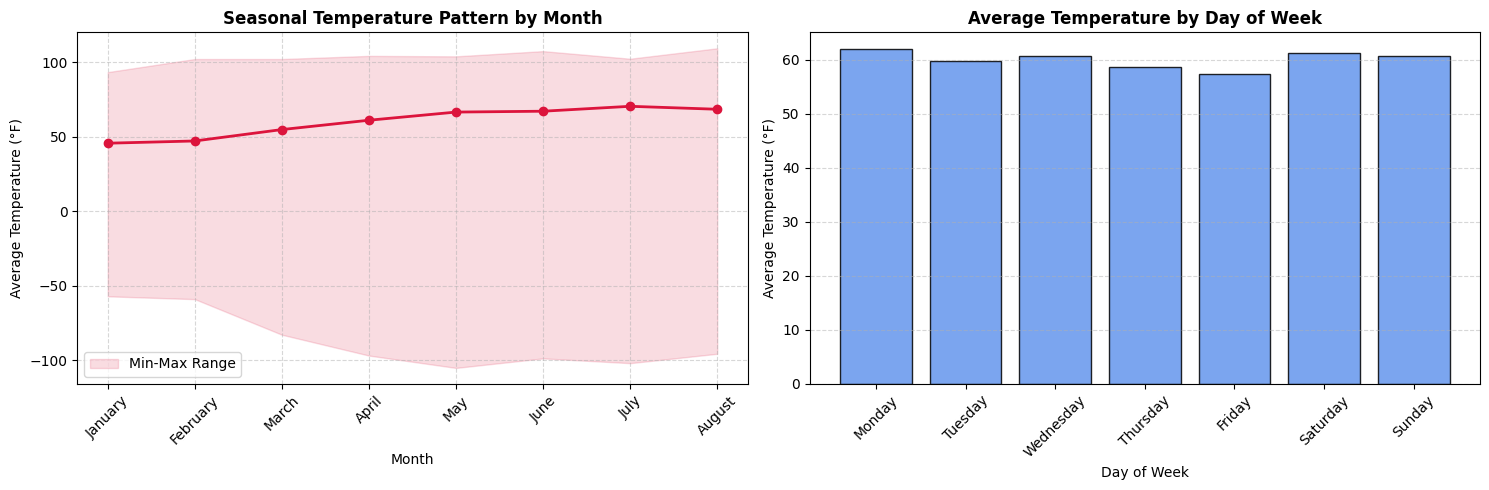

In [7]:
df_time = df.set_index('date').sort_index()

df_time['month_num'] = df_time.index.month             
df_time['month_name'] = df_time.index.month_name()     
df_time['day_of_week'] = df_time.index.day_name()      
df_time['day_of_week_num'] = df_time.index.dayofweek  

print(df_time[['temp', 'month_name', 'day_of_week']].head())

monthly_summary = df_time.groupby(['month_num', 'month_name'])['temp'].agg(
    avg_temp='mean',
    min_temp='min',
    max_temp='max',
    count='count'
).reset_index()

print("--- Monthly Seasonal Averages ---")
print(monthly_summary)

weekday_order = ['Monday', 'Tuesday', 'Wednesday', 'Thursday', 'Friday', 'Saturday', 'Sunday']

dow_summary = df_time.groupby('day_of_week')['temp'].agg(['mean', 'std', 'count']).reindex(weekday_order)

print("\n--- Day-of-Week Averages ---")
print(dow_summary)

month_dow_pivot = df_time.pivot_table(
    index='month_name',
    columns='day_of_week',
    values='temp',
    aggfunc='mean'
)[weekday_order]

print("\n--- Monthly vs Day-of-Week Matrix ---")
print(month_dow_pivot)


fig, axes = plt.subplots(1, 2, figsize=(15, 5))

axes[0].plot(monthly_summary['month_name'], monthly_summary['avg_temp'], marker='o', color='crimson', linewidth=2)
axes[0].fill_between(
    monthly_summary['month_name'],
    monthly_summary['min_temp'],
    monthly_summary['max_temp'],
    alpha=0.15,
    color='crimson',
    label='Min-Max Range'
)
axes[0].set_title('Seasonal Temperature Pattern by Month', fontweight='bold')
axes[0].set_xlabel('Month')
axes[0].set_ylabel('Average Temperature (°F)')
axes[0].tick_params(axis='x', rotation=45)
axes[0].grid(True, linestyle='--', alpha=0.5)
axes[0].legend()

axes[1].bar(dow_summary.index, dow_summary['mean'], color='cornflowerblue', edgecolor='black', alpha=0.85)
axes[1].set_title('Average Temperature by Day of Week', fontweight='bold')
axes[1].set_xlabel('Day of Week')
axes[1].set_ylabel('Average Temperature (°F)')
axes[1].tick_params(axis='x', rotation=45)
axes[1].grid(True, linestyle='--', alpha=0.5, axis='y')

plt.tight_layout()
plt.show()

## 6. Raw observations, 30-day trend and monthly averages

The raw station observations are drawn as a scatter layer behind the daily mean, 30-day rolling average and monthly resampled average, all in one figure.

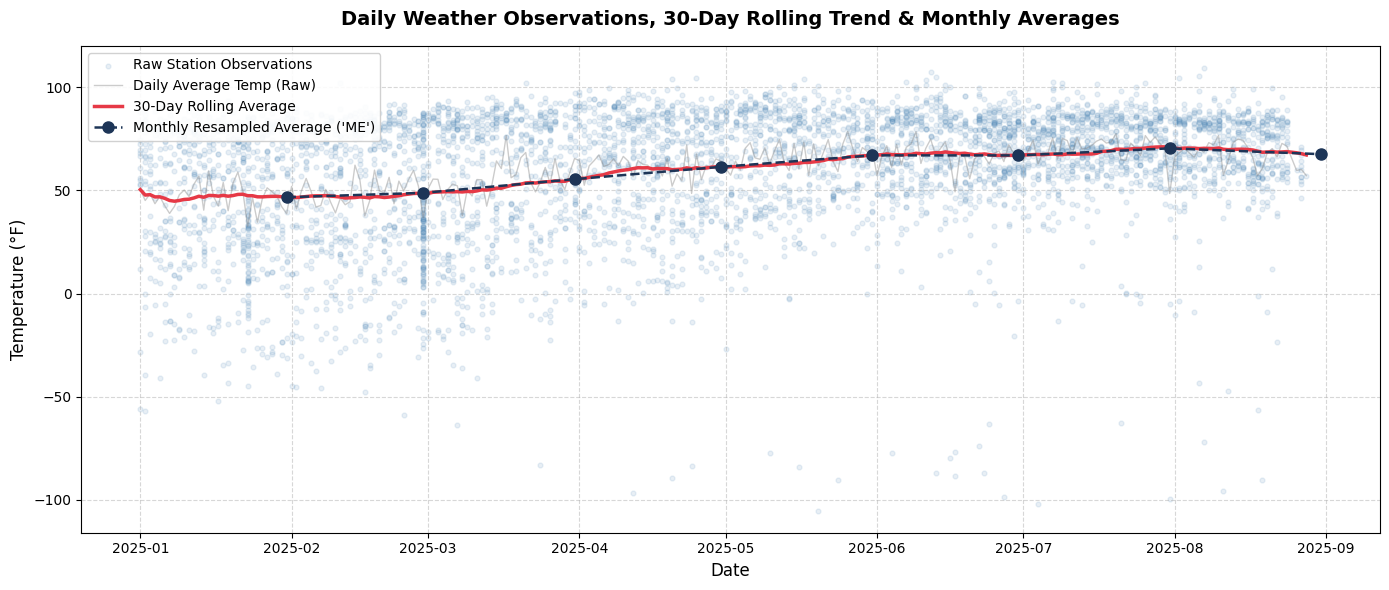

In [8]:
daily_temp = df.groupby('date')['temp'].mean().sort_index()

rolling_30d = daily_temp.rolling(window=30, min_periods=1).mean()

monthly_temp = daily_temp.resample('ME').mean()

plt.figure(figsize=(14, 6))

# Layer 1: raw station observations (drawn first so they sit behind the lines)
plt.scatter(
    df['date'],
    df['temp'],
    color='steelblue',
    alpha=0.12,
    s=12,
    label='Raw Station Observations'
)

plt.plot(
    daily_temp.index,
    daily_temp.values,
    label='Daily Average Temp (Raw)',
    color='gray',
    alpha=0.4,
    linewidth=1
)

plt.plot(
    rolling_30d.index,
    rolling_30d.values,
    label='30-Day Rolling Average',
    color='#E63946',
    linewidth=2.5
)

plt.plot(
    monthly_temp.index,
    monthly_temp.values,
    label="Monthly Resampled Average ('ME')",
    color='#1D3557',
    marker='o',
    markersize=8,
    linestyle='--',
    linewidth=1.8
)

plt.title('Daily Weather Observations, 30-Day Rolling Trend & Monthly Averages', fontsize=14, fontweight='bold', pad=15)
plt.xlabel('Date', fontsize=12)
plt.ylabel('Temperature (°F)', fontsize=12)
plt.legend(frameon=True, facecolor='white', framealpha=0.9, loc='upper left', fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()

plt.show()

## 7. Summary of findings

- **Seasonality:** average temperature climbs steadily through the record. January is the coolest month (about 45.7 °F) and July is the warmest (about 70.4 °F), a spread of roughly 25 °F between monthly averages. August dips slightly (about 68.5 °F), but the data ends on 28 August so it is a partial month.
- **Day of week:** average temperature by weekday ranges only from about 57.4 °F (Friday) to 62.0 °F (Monday), with a standard deviation near 29 °F on every day. There is no meaningful weekday effect, as expected for a weather variable. The differences come from which stations reported on which days, not from the weekday itself.
- **Trend:** the 30-day rolling average rises from about 50 °F at the start of January to a peak of about 71 °F on 29 July, then eases to about 67 °F by the end of August. The monthly resampled averages follow the same path.
- **Spread:** individual station readings range from roughly -105 °F to 109 °F, so the scatter around the averages is wide. The data mixes many stations across different climates, which is also why the averages rise smoothly and show a weaker seasonal swing than a single location would.
- **Data notes:** observations cover 1 January to 28 August 2025 (239 of 240 days; one date has no data), with about 21 station readings per date on average. Observations were averaged by date before rolling and resampling. Because the record covers only eight months, it shows the warming half of the annual cycle rather than a full year.